# 데이터셋 로딩

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
)

RANDOM_STATE = 42

# 노트북 위치에 따라 경로를 수정하세요.
# 예: SKAB 저장소 루트에서 실행한다면 Path("data")
DATA_ROOT = Path("assets/SKAB_0.9.0")

# "normal_only" 또는 "official_split"
EXPERIMENT_MODE = "official_split" # "normal_only"

# normal_only 모드에서 정상 Validation 점수의 상위 5%를 이상으로 판정
# 즉, Validation 정상 데이터 기준 목표 FAR 약 5%
TARGET_VALIDATION_FAR = 0.05

# Isolation Forest 설정
N_ESTIMATORS = 100
MAX_SAMPLES = "auto"
CONTAMINATION = "auto"

# StandardScaler는 Train 데이터에만 fit하고 Validation/Test에는 transform만 적용합니다.
USE_STANDARD_SCALER = False

print("DATA_ROOT:", DATA_ROOT.resolve())
print("EXPERIMENT_MODE:", EXPERIMENT_MODE)

DATA_ROOT: C:\github\CBNU.Master.1yr.apprentice\prj3\assets\SKAB_0.9.0
EXPERIMENT_MODE: official_split


In [ ]:
LABEL_COLUMNS = {"anomaly", "changepoint"}
TIME_CANDIDATES = ("datetime", "timestamp", "time", "date")


def find_anomaly_free_file(data_root: Path) -> Path:
    candidates = list(data_root.rglob("anomaly-free.csv"))
    if not candidates:
        raise FileNotFoundError(
            f"'anomaly-free.csv'를 찾지 못했습니다. DATA_ROOT를 확인하세요: {data_root.resolve()}"
        )
    if len(candidates) > 1:
        print("anomaly-free.csv 후보가 여러 개입니다. 첫 번째 파일을 사용합니다:")
        for p in candidates:
            print(" -", p)
    return candidates[0]


def read_skab_csv(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, sep=";")

    # 시간 컬럼을 인덱스로 설정 (있는 경우)
    time_col = next((c for c in TIME_CANDIDATES if c in anomaly_free_anomaly_free_anomaly_free_anomaly_free_anomaly_free_df.columns), None)
    if time_col is not None:
        anomaly_free_anomaly_free_anomaly_free_anomaly_free_anomaly_free_anomaly_free_df[time_col] = pd.to_datetime(df[time_col], errors="coerce")
        df = anomaly_free_anomaly_free_anomaly_free_anomaly_free_df.set_index(time_col)

    # 숫자형 컬럼 변환
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    return df


anomaly_free_path = find_anomaly_free_file(DATA_ROOT)
anomaly_free_df = read_skab_csv(anomaly_free_path)

print("Anomaly-free file:", anomaly_free_path)
print("Shape:", anomaly_free_df.shape)
display(anomaly_free_df.head())
print("Columns:", anomaly_free_df.columns.tolist())

Anomaly-free file: assets\SKAB_0.9.0\anomaly-free\anomaly-free.csv
Shape: (9405, 8)


,Accelerometer1RMS,Accelerometer2RMS,Current,Pressure,Temperature,Thermocouple,Voltage,Volume Flow RateRMS
datetime,,,,,,,,
2020-02-08 13:30:47,0.202394,0.275154,2.16975,0.382638,90.6454,26.8508,238.852,122.664
2020-02-08 13:30:48,0.203153,0.277857,2.07999,-0.273216,90.7978,26.8639,227.943,122.338
2020-02-08 13:30:50,0.202054,0.275790,2.52577,0.382638,90.7730,26.8603,223.486,121.338
2020-02-08 13:30:51,0.203595,0.278101,2.49742,0.054711,90.8424,26.8616,244.904,121.664
2020-02-08 13:30:52,0.201889,0.276363,2.29194,0.710565,90.6664,26.8603,239.196,122.000


Columns: ['Accelerometer1RMS', 'Accelerometer2RMS', 'Current', 'Pressure', 'Temperature', 'Thermocouple', 'Voltage', 'Volume Flow RateRMS']


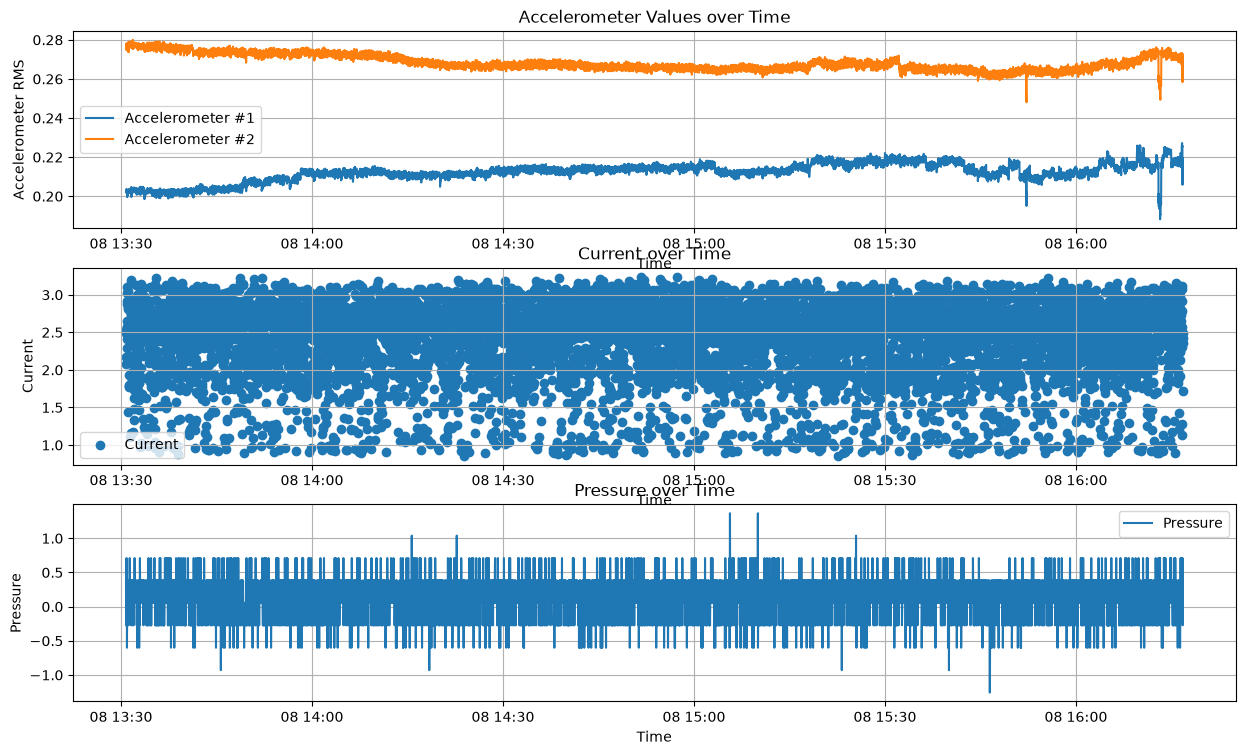

In [ ]:
anomaly_free_df.index = pd.to_datetime(anomaly_free_df.index)

plt.figure(figsize=(15, 21))
plt.subplot(7, 1, 1)
plt.plot(anomaly_free_df.index, anomaly_free_df['Accelerometer1RMS'], label='Accelerometer #1')
plt.plot(anomaly_free_df.index, anomaly_free_df['Accelerometer2RMS'], label='Accelerometer #2')
plt.title('Accelerometer Values over Time')
plt.xlabel('Time')
plt.ylabel('Accelerometer RMS')
plt.legend()
plt.grid()

plt.subplot(7, 1, 2)
plt.scatter(anomaly_free_df.index, anomaly_free_df['Current'], label='Current')
plt.title('Current over Time')
plt.xlabel('Time')
plt.ylabel('Current')
plt.legend()
plt.grid()

plt.subplot(7, 1, 3)
plt.plot(anomaly_free_df.index, anomaly_free_df['Pressure'], label='Pressure')
plt.title('Pressure over Time')
plt.xlabel('Time')
plt.ylabel('Pressure')
plt.legend()
plt.grid()

plt.subplot(7, 1, 4)
plt.plot(anomaly_free_df.index, anomaly_free_df['Temperature'], label='Temperature')
plt.title('Temperature over Time')
plt.xlabel('Time')
plt.ylabel('Temperature')
plt.legend()
plt.grid()

plt.subplot(7, 1, 5)
plt.plot(anomaly_free_df.index, anomaly_free_df['Thermocouple'], label='Thermocouple')
plt.title('Thermocouple over Time')
plt.xlabel('Time')
plt.ylabel('Thermocouple')
plt.legend()
plt.grid()

plt.subplot(7, 1, 6)
plt.plot(anomaly_free_df.index, anomaly_free_df['Voltage'], label='Voltage')
plt.title('Voltage over Time')
plt.xlabel('Time')
plt.ylabel('Voltage')
plt.legend()
plt.grid()

plt.subplot(7, 1, 7)
plt.plot(anomaly_free_df.index, anomaly_free_df['Volume Flow RateRMS'], label='Volume Flow RateRMS')
plt.title('Volume Flow RateRMS over Time')
plt.xlabel('Time')
plt.ylabel('Volume Flow RateRMS')
plt.legend()
plt.grid()

plt.show()